# Tutorial 5: Advanced binning

**Author:** Hannu Parviainen <br>
**Edited:** 22 August 2024

We have already seen how to add radius ratio knots to increase local transmission spectrum resolution.

In [1]:
%run ../setup_multiprocessing.py

In [2]:
%matplotlib inline

In [3]:
from multiprocessing import Pool
from xarray import load_dataset
from scipy.interpolate import splev, splrep
from numpy import array, geomspace, linspace, diff, newaxis, r_
from matplotlib.pyplot import subplots, setp

from easyts import EasyTS, TSData, Binning, load_model

## Data preparation

We begin by reading in the data set as usual.

In [4]:
def read_data(fname):
    with load_dataset(fname) as ds:
        return TSData(time=ds.time.values, wavelength=ds.wavelength.values, fluxes=ds.flux.values, errors=ds.error.values)

In [ ]:
d1 = read_data('data/nirHiss_order_1.h5', "WASP-39b JWST NIRISS Order 1")
d1.remove_outliers()

In [5]:
d1 = read_data('data/nirHiss_order_1.h5')
d1.remove_outliers()
d1.crop_wavelength(0.9, 3.0)
d2 = read_data('data/nirHiss_order_2.h5')
d2.crop_wavelength(0.0, 0.9)
d2.remove_outliers()
dr = d2 + d1

## Heterogeneous binning

Previously, we've used the `TSData.bin_wavelength` method to bin the data to a given spectroscopic resolution. Now, instead, we create a heterogeneous `ComboundBinning` object by concatenating three `Binning` objects together. A `Binning` object is initialised with the minimum and maximum wavelengths and either a spectral resolution `r`, number of bins `nb`, or bin width `bw`.

In [6]:
nraw = ((dr.wavelength >= 0.72) & (dr.wavelength <= 0.9)).sum()
binning = Binning(dr.bbox_wl[0], 0.72, r=200) + Binning(0.72, 0.9, nb=nraw) + Binning(0.9, dr.bbox_wl[1], r=100)
binning

CompoundBinning:
BinningRange 0.5699 - 0.7200: dx =    nan, n =   47, R = 200
BinningRange 0.7200 - 0.9000: dx = 0.0005, n =  392, R = None
BinningRange 0.9000 - 2.8282: dx =    nan, n =  115, R = 100

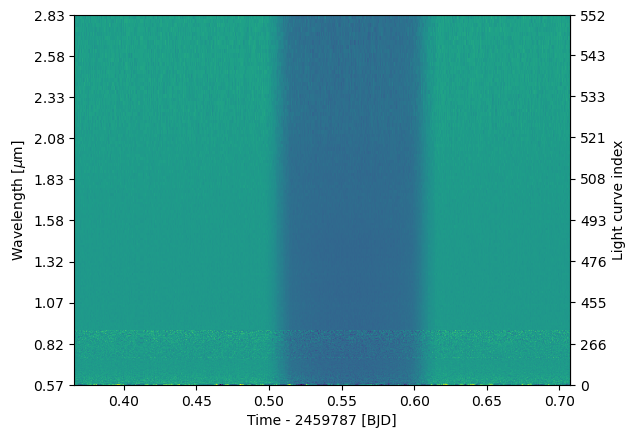

In [7]:
db = dr.bin_wavelength(binning)
db.errors[:,:] = diff(db.fluxes).std(1)[:,newaxis]
ax = db.plot()

In [8]:
ts = load_model("01a_lowres_power2.fits", name='05a')
ts.set_data(db)

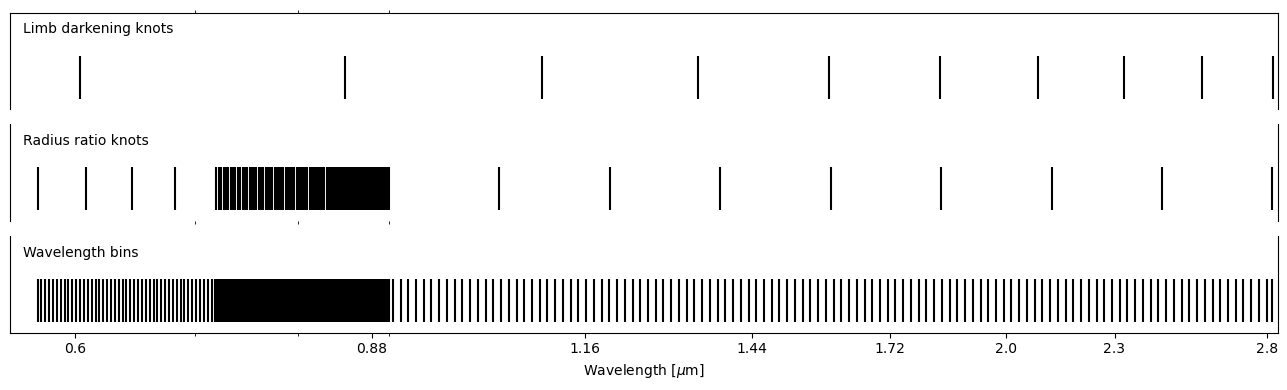

In [9]:
knots = r_[linspace(db.bbox_wl[0], 0.72, 5), linspace(0.72, 0.90, 81), geomspace(0.90, db.bbox_wl[1], 9)]
ts.set_radius_ratio_knots(knots)
ts.set_radius_ratio_prior('UP', 0.14, 0.15)
ts.plot_setup(xscale='log', xticks=[0.6, 0.88, 1.16, 1.44, 1.72, 2.0, 2.30, 2.8]);
ts.fit_white()
ts.normalize_baseline(1)

In [10]:
def lnpostf(pv):
    return ts.lnposterior(pv)

pool = Pool(8)

In [12]:
x0 = ts.create_initial_population(250, 'mcmc', add_noise=True)

Global optimisation:   0%|          | 0/2500 [00:00<?, ?it/s]

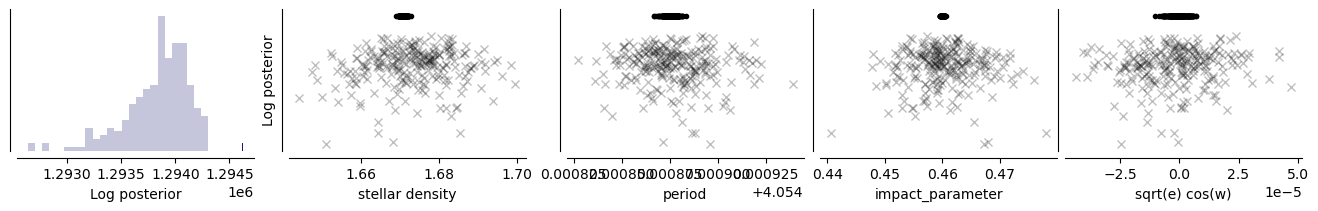

In [15]:
ts.fit(niter=2500, pool=pool, lnpost=lnpostf, initial_population=x0)

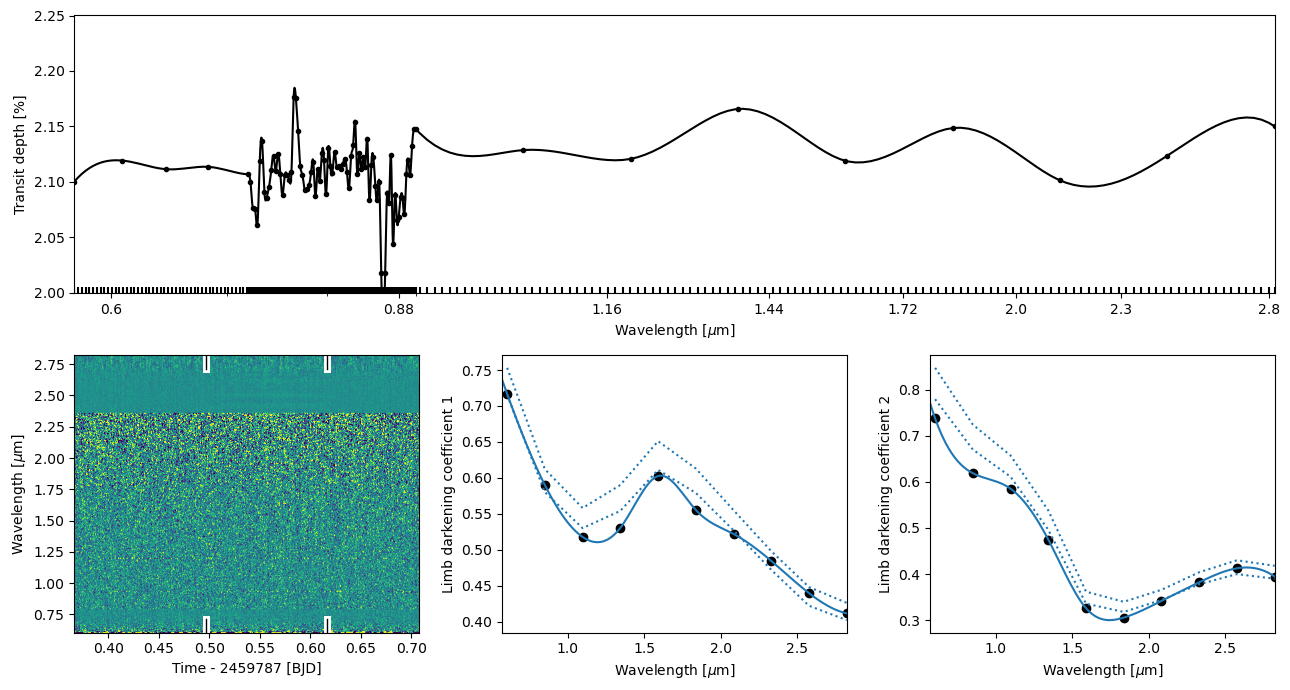

In [20]:
ts.plot_fit(result='fit', figsize=(13,7), 
            res_args=dict(pmin=5, pmax=95),
            trs_args=dict(xscale='log', ylim=(2.0,2.25), xticks=[0.6, 0.88, 1.16, 1.44, 1.72, 2.0, 2.30, 2.8]))

In [17]:
ts.reset_sampler()

In [21]:
ts.sample(1000, thin=100, repeats=3, pool=pool, lnpost=lnpostf)

MCMC sampling:   0%|          | 0/3 [00:00<?, ?it/s]

Run 1/3:   0%|          | 0/1000 [00:00<?, ?it/s]

Run 2/3:   0%|          | 0/1000 [00:00<?, ?it/s]

Run 3/3:   0%|          | 0/1000 [00:00<?, ?it/s]

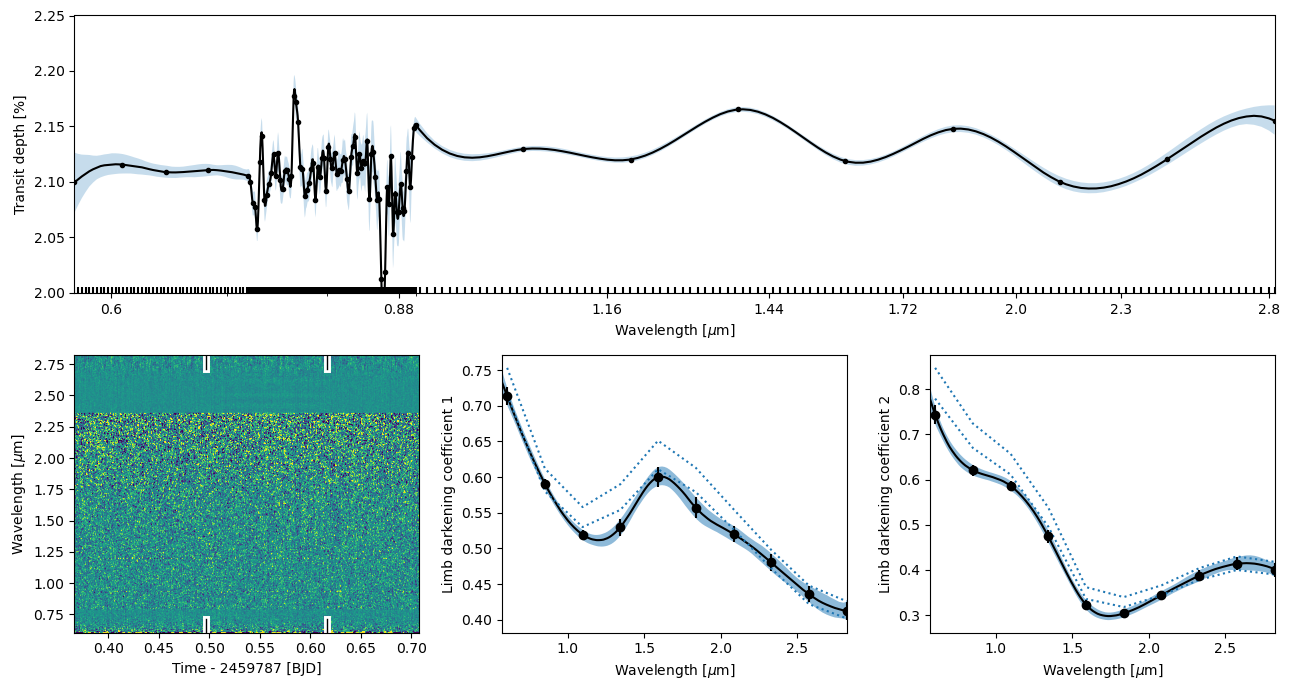

In [19]:
ts.plot_fit(result='mcmc', figsize=(13,7), 
            res_args=dict(pmin=5, pmax=95),
            trs_args=dict(xscale='log', ylim=(2.0,2.25), xticks=[0.6, 0.88, 1.16, 1.44, 1.72, 2.0, 2.30, 2.8]))

In [157]:
tsb.sample(1000, thin=100, repeats=3, pool=pool, lnpost=lnpostf)

MCMC sampling:   0%|          | 0/3 [00:00<?, ?it/s]

Run 1/3:   0%|          | 0/1000 [00:00<?, ?it/s]

Run 2/3:   0%|          | 0/1000 [00:00<?, ?it/s]

Run 3/3:   0%|          | 0/1000 [00:00<?, ?it/s]

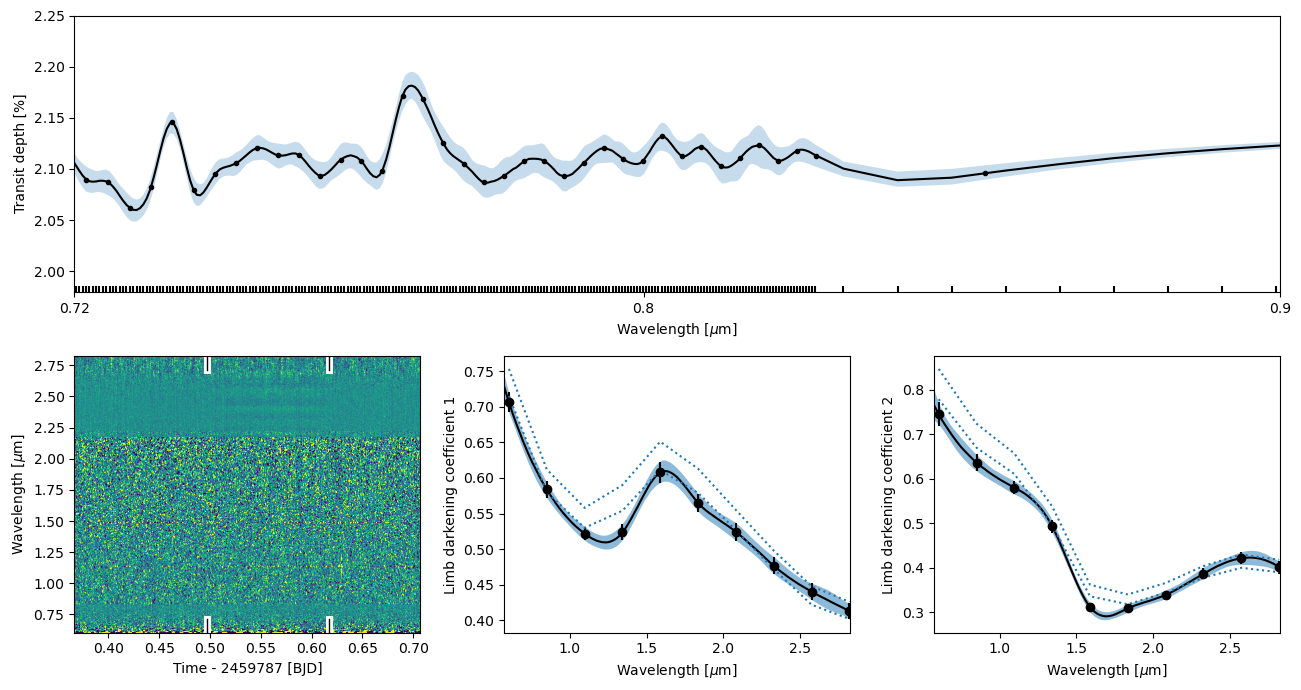

In [29]:
fig = ts.plot_fit(result='mcmc', figsize=(13,7), 
            res_args=dict(pmin=5, pmax=95),
            trs_args=dict(xscale='log', ylim=(1.98,2.25), xticks=[0.72, 0.8, 0.9]))
setp(fig.axes[1], xlim=(0.72, 0.9))
fig

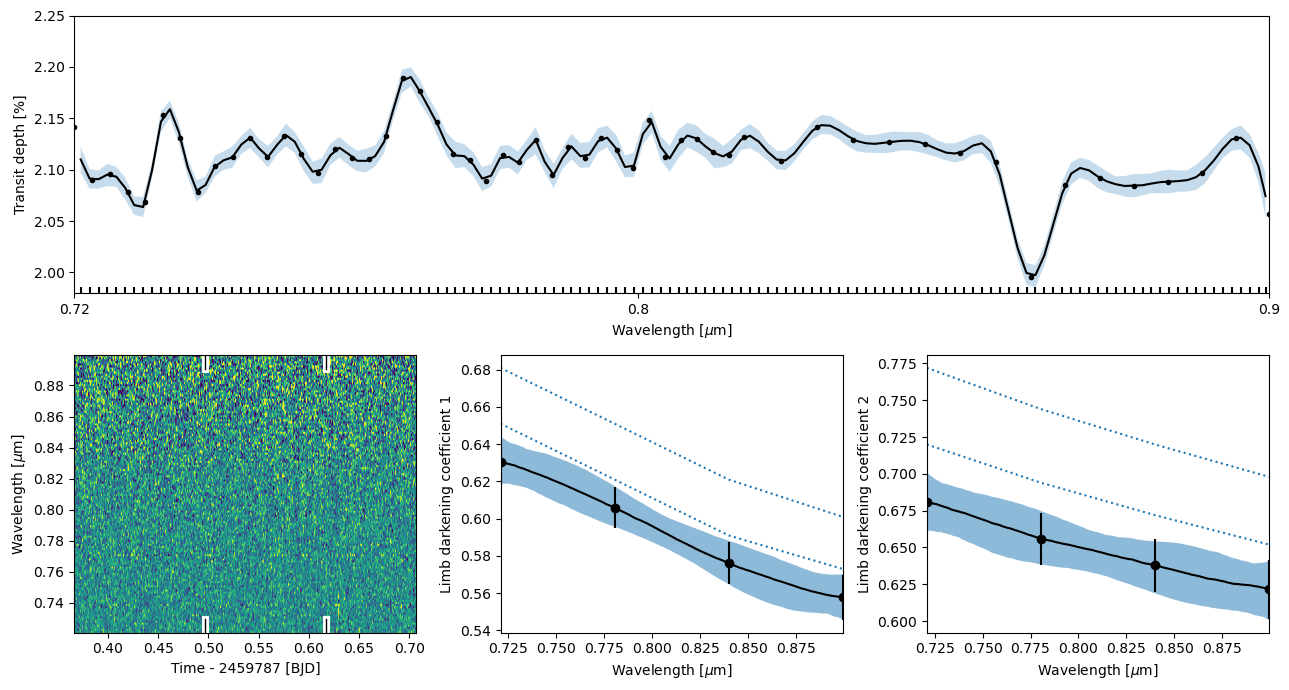

In [164]:
tsb.plot_fit(result='mcmc', figsize=(13,7), 
            res_args=dict(pmin=5, pmax=95),
            trs_args=dict(xscale='log', ylim=(1.98,2.25), xticks=[0.72, 0.8, 0.9]))

In [149]:
s0 = ts.get_transmission_spectrum()

In [159]:
s1 = tsb.get_transmission_spectrum()

In [160]:
s0

,depth,depth_e,depth_eneg,depth_epos
wavelength,,,,
0.721463,0.020884,0.000086,-0.000086,0.000087
0.723872,0.020810,0.000083,-0.000085,0.000081
0.726289,0.020740,0.000069,-0.000074,0.000064
0.728714,0.020760,0.000074,-0.000069,0.000080
0.731147,0.020968,0.000072,-0.000072,0.000073
...,...,...,...,...
2.266899,0.020815,0.000104,-0.000097,0.000111
2.274468,0.020893,0.000115,-0.000112,0.000118
2.282062,0.020936,0.000110,-0.000103,0.000117


[0.72, 0.9]

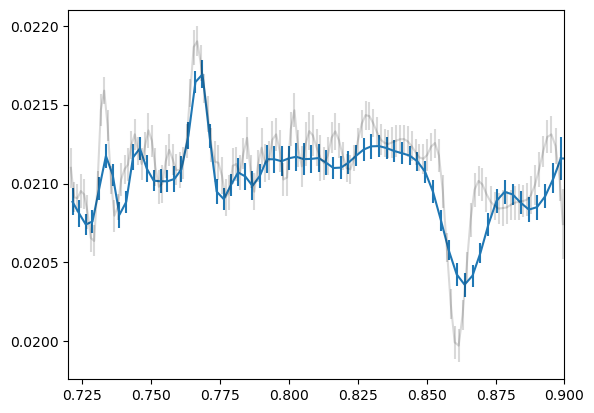

In [163]:
fig, ax = subplots()
ax.errorbar(s0.index, s0.depth, s0.depth_e)
ax.errorbar(s1.index, s1.depth, s1.depth_e, c='k', alpha=0.15)

setp(ax, xlim=(0.72, 0.9))

---

<center>&copy;2024 Hannu Parviainen</center>